<a href="https://colab.research.google.com/github/ThembaMapundu/MMA3001-Project/blob/main/notebooks/Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded: 42843 records
Sensor: 6012002000869
Valid measurements: 13800
First: 2024-02-29T06:04:56
Last: 2024-06-13T17:45:44
1 missing points: 4927 eligible starting positions
3 missing points: 3066 eligible starting positions
6 missing points: 526 eligible starting positions
12 missing points: 129 eligible starting positions
Gap size 1: 30 of 30 trials selected
Gap size 3: 30 of 30 trials selected
Gap size 6: 30 of 30 trials selected
Gap size 12: 1 of 30 trials selected

Total method evaluations: 273
Successful evaluations: 273
VALIDATION SUMMARY


,Gap Size,Method,Trials,MAE (ppm),RMSE (ppm),Mean runtime (ms),Failures
0,1,Linear,30,7.5840,9.2269,0.0053,0
1,1,Cubic Spline,30,9.6775,11.3717,0.2610,0
2,1,PCHIP,30,7.7004,9.2634,0.2860,0
3,3,Linear,30,7.8667,9.9222,0.0053,0
4,3,Cubic Spline,30,10.8044,13.9777,0.2811,0
5,3,PCHIP,30,8.1615,10.2647,0.2968,0
6,6,Linear,30,8.5303,11.0103,0.0049,0
7,6,Cubic Spline,30,15.7394,20.6465,0.2449,0
8,6,PCHIP,30,8.9901,11.6086,0.2761,0
9,12,Linear,1,22.2497,24.4229,0.0072,0


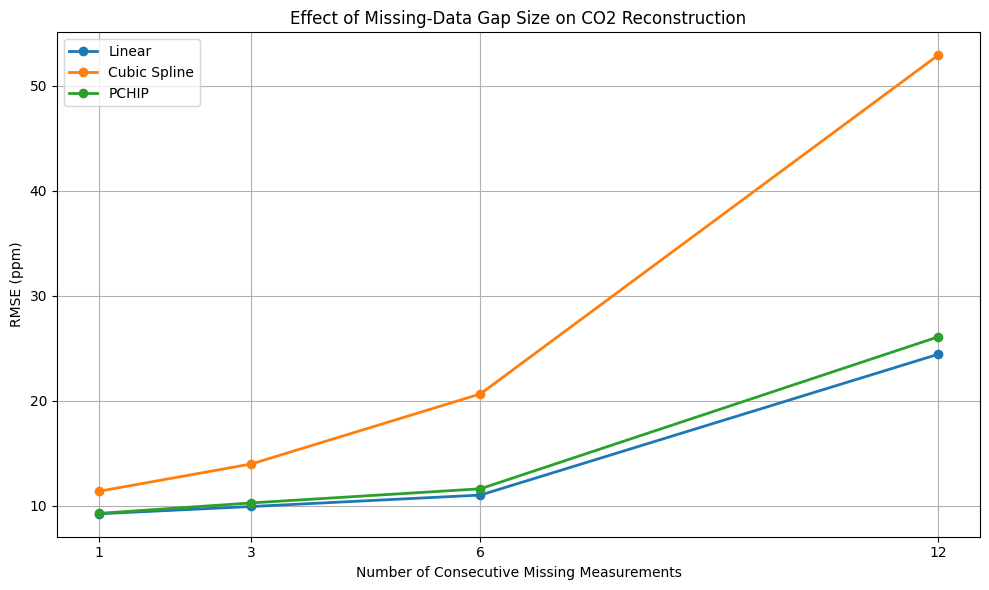

In [3]:

# INTERPOLATION VALIDATION

#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import CubicSpline, PchipInterpolator
from time import perf_counter

# Change to your GitHub details
url = (f"https://raw.githubusercontent.com/ThembaMapundu/MMA3001-Project/main/SourceData/co2_clean.xlsx")

data = pd.read_excel(url, engine="openpyxl")

print("Dataset loaded:", len(data), "records")

#  PREPARE SENSOR DATA
def prepare_sensor_data(data, sensor_id):
    """
    Extract valid CO2 measurements for one sensor.

    Parameters
    ----------
    data : pandas.DataFrame
        Dataset containing sensor IDs, UTC timestamps
        and CO2 concentrations.

    sensor_id : int
        Sensor to analyse.

    Returns
    -------
    time : ndarray
        Sorted UTC timestamps as datetime64[s].

    co2 : ndarray
        Valid CO2 concentrations in ppm.
    """

    ids = pd.to_numeric(data["sensor_id"], errors="coerce")
    selected = data.loc[ids == sensor_id].copy()

    timestamps = pd.to_datetime(selected["timestamp_utc"],errors="coerce",utc=True)

    time = (timestamps.dt.tz_localize(None).to_numpy(dtype="datetime64[s]"))

    co2 = pd.to_numeric(selected["co2_ppm"],errors="coerce").to_numpy(dtype=float)

    valid = ((~np.isnat(time))& np.isfinite(co2)& (co2 > 0))

    time = time[valid]
    co2 = co2[valid]

    order = np.argsort(time)
    time = time[order]
    co2 = co2[order]

    # Consolidate repeated timestamps
    unique_time, inverse = np.unique(time, return_inverse=True)

    co2 = np.array([np.median(co2[inverse == i])for i in range(len(unique_time))
  ])

    if len(unique_time) < 14:
        raise ValueError("Insufficient sensor observations.")

    return unique_time, co2

#use sensor that was selected
sensor_id = 6012002000869

time, co2 = prepare_sensor_data(data, sensor_id)

print("Sensor:", sensor_id)
print("Valid measurements:", len(co2))
print("First:", time[0])
print("Last:", time[-1])

# INTERPOLATION AND ERROR FUNCTIONS

def linear_interpolation(x_known, y_known, x_query):
    """
    Estimate CO2 using linear interpolation.

    Inputs
    ------
    x_known : ndarray
        Known times in elapsed minutes.
    y_known : ndarray
        Known concentrations in ppm.
    x_query : ndarray
        Missing times in elapsed minutes.

    Returns
    -------
    ndarray
        Reconstructed CO2 values in ppm.
    """
    return np.interp(x_query, x_known, y_known)


def cubic_spline_interpolation(x_known, y_known, x_query):
    """
    Estimate CO2 using a natural cubic spline.

    Returns reconstructed CO2 values in ppm.
    """
    model = CubicSpline(
        x_known, y_known, bc_type="natural"
    )
    return model(x_query)


def pchip_interpolation(x_known, y_known, x_query):
    """
    Estimate CO2 using shape-preserving PCHIP.

    Returns reconstructed CO2 values in ppm.
    """
    model = PchipInterpolator(x_known, y_known)
    return model(x_query)


def calculate_errors(y_true, y_pred):
    """
    Calculate MAE and RMSE for CO2 reconstruction.

    Both outputs are expressed in ppm.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if (
        y_true.shape != y_pred.shape
        or y_true.size == 0
        or not np.all(np.isfinite(y_pred))
    ):
        raise ValueError("Invalid reconstruction values.")

    error = y_true - y_pred

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))

    return mae, rmse


methods = {
    "Linear": linear_interpolation,
    "Cubic Spline": cubic_spline_interpolation,
    "PCHIP": pchip_interpolation
}

# FIND VALID EXPERIMENTAL GAPS

def find_valid_gaps(time, gap_size, padding=4):
    """
    Find gap positions with regular sampling.

    Parameters
    ----------
    time : ndarray
        Sorted timestamps.

    gap_size : int
        Number of consecutive readings to hide.

    padding : int
        Number of known readings required on each side.

    Returns
    -------
    ndarray
        Eligible starting indices of hidden gaps.
    """
    if gap_size < 1 or padding < 2:
        raise ValueError("Invalid gap or padding size.")

    dt = np.diff(time) / np.timedelta64(1, "m")
    regular = (dt >= 8) & (dt <= 12)

    # A full window has gap_size + 2*padding readings
    window_size = gap_size + 2 * padding
    required_intervals = window_size - 1

    # Count irregular intervals in rolling windows
    bad = (~regular).astype(int)
    cumulative = np.r_[0, np.cumsum(bad)]

    starts = np.arange(
        padding,
        len(time) - gap_size - padding + 1
    )

    # Full window begins padding readings before the gap
    window_start = starts - padding

    bad_counts = (
        cumulative[window_start + required_intervals]
        - cumulative[window_start]
    )

    return starts[bad_counts == 0]


# Experimental gap sizes
gap_sizes = [1, 3, 6, 12]

for gap_size in gap_sizes:
    candidates = find_valid_gaps(time, gap_size)
    print(
        f"{gap_size} missing points: "
        f"{len(candidates)} eligible starting positions"
    )

# 5. REPEATED VALIDATION EXPERIMENTS

def run_validation(
    time,
    co2,
    gap_sizes=(1, 3, 6, 12),
    n_trials=30,
    seed=42,
    padding=4
):
    """
    Validate interpolation methods over repeated artificial gaps.

    Parameters
    ----------
    time : ndarray
        Original timestamps, sorted chronologically.

    co2 : ndarray
        Original CO2 measurements in ppm.

    gap_sizes : tuple
        Number of consecutive readings removed per gap.

    n_trials : int
        Maximum number of non-overlapping gaps per size.

    seed : int
        Random seed for reproducible gap selection.

    padding : int
        Known measurements retained on either side.

    Returns
    -------
    records : list of dict
        Individual trial results, including MAE, RMSE,
        runtime, failure status and gap location.

    predictions : list of dict
        Original and reconstructed readings for
        each successful trial.
    """

    rng = np.random.default_rng(seed)

    # Convert timestamps to elapsed minutes
    x = (
        (time - time[0]) / np.timedelta64(1, "m")
    ).astype(float)

    records = []
    predictions = []

    # Track occupied regions so selected fitting windows
    # do not overlap across experiments
    used = np.zeros(len(co2), dtype=bool)

    for gap_size in gap_sizes:

        candidates = find_valid_gaps(
            time, gap_size, padding=padding
        )

        # Shuffle positions reproducibly
        candidates = rng.permutation(candidates)

        selected = []

        for start in candidates:

            left = start - padding
            right = start + gap_size + padding

            if not np.any(used[left:right]):
                selected.append(int(start))
                used[left:right] = True

            if len(selected) >= n_trials:
                break

        print(
            f"Gap size {gap_size}: "
            f"{len(selected)} of {n_trials} trials selected"
        )

        for trial, start in enumerate(selected, start=1):

            missing_idx = np.arange(
                start, start + gap_size
            )

            left = start - padding
            right = start + gap_size + padding

            local_idx = np.arange(left, right)

            # Preserve original hidden values
            y_true = co2[missing_idx].copy()

            # Artificially hide measurements
            observed = co2[local_idx].copy()

            missing_local = np.arange(
                padding, padding + gap_size
            )

            observed[missing_local] = np.nan

            # Train only on available measurements
            known = np.isfinite(observed)

            x_known = x[local_idx][known]
            y_known = observed[known]
            x_query = x[missing_idx]

            for name, method in methods.items():

                start_timer = perf_counter()

                try:
                    estimated = method(
                        x_known, y_known, x_query
                    )

                    runtime = perf_counter() - start_timer

                    estimated = np.asarray(
                        estimated, dtype=float
                    )

                    mae, rmse = calculate_errors(
                        y_true, estimated
                    )

                    # Flag physically implausible estimates
                    nonpositive = int(
                        np.sum(estimated <= 0)
                    )

                    status = "success"

                    predictions.append({
                        "gap_size": gap_size,
                        "trial": trial,
                        "start_index": start,
                        "method": name,
                        "true": y_true.copy(),
                        "estimated": estimated.copy()
                    })

                except (ValueError, RuntimeError,
                        FloatingPointError) as exc:

                    runtime = perf_counter() - start_timer

                    mae = np.nan
                    rmse = np.nan
                    nonpositive = 0
                    status = f"failed: {exc}"

                records.append({
                    "gap_size": gap_size,
                    "trial": trial,
                    "start_index": start,
                    "method": name,
                    "MAE": mae,
                    "RMSE": rmse,
                    "runtime_s": runtime,
                    "nonpositive": nonpositive,
                    "status": status
                })

    return records, predictions


# Run the experiments
records, predictions = run_validation(
    time,
    co2,
    gap_sizes=(1, 3, 6, 12),
    n_trials=30,
    seed=42
)

print("\nTotal method evaluations:", len(records))
print("Successful evaluations:", sum(
    r["status"] == "success" for r in records
))


# 6. SUMMARISE VALIDATION RESULTS
summary = []

for gap_size in gap_sizes:

    for method_name in methods:

        trials = [
            r for r in records
            if r["gap_size"] == gap_size
            and r["method"] == method_name
        ]

        successful = [
            r for r in trials
            if r["status"] == "success"
        ]

        matched = [
            p for p in predictions
            if p["gap_size"] == gap_size
            and p["method"] == method_name
        ]

        if len(successful) == 0:
            summary.append({
                "Gap Size": gap_size,
                "Method": method_name,
                "Trials": 0,
                "MAE (ppm)": np.nan,
                "RMSE (ppm)": np.nan,
                "Mean runtime (ms)": np.nan,
                "Failures": len(trials)
            })
            continue

        # Combine every reconstructed measurement
        all_true = np.concatenate([
            p["true"] for p in matched
        ])

        all_pred = np.concatenate([
            p["estimated"] for p in matched
        ])

        mae, rmse = calculate_errors(
            all_true, all_pred
        )

        runtime_ms = 1000 * np.mean([
            r["runtime_s"] for r in successful
        ])

        summary.append({
            "Gap Size": gap_size,
            "Method": method_name,
            "Trials": len(successful),
            "MAE (ppm)": mae,
            "RMSE (ppm)": rmse,
            "Mean runtime (ms)": runtime_ms,
            "Failures": len(trials) - len(successful)
        })

summary_df = pd.DataFrame(summary)

print("VALIDATION SUMMARY")
display(summary_df.round(4))

# 7. GRAPH: RMSE VS MISSING-DATA GAP SIZE

plt.figure(figsize=(10, 6))

for method_name in methods:

    subset = summary_df[
        summary_df["Method"] == method_name
    ].sort_values("Gap Size")

    plt.plot(
        subset["Gap Size"],
        subset["RMSE (ppm)"],
        marker="o",
        linewidth=2,
        label=method_name
    )

plt.xlabel("Number of Consecutive Missing Measurements")
plt.ylabel("RMSE (ppm)")
plt.title("Effect of Missing-Data Gap Size on CO2 Reconstruction")

plt.xticks(gap_sizes)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
